# Waikato Research Commons Data Collection and Analysis

In [ ]:
!pip -q install requests pandas tqdm openpyxl

In [ ]:
import re
import time
import unicodedata

import requests
import pandas as pd
from tqdm.auto import tqdm

BASE = "https://researchcommons.waikato.ac.nz"
COLLECTION_UUID = "c04b1b5e-510a-466b-b0fc-513765b3b6ee"   # Higher Degree Theses
API_URL = f"{BASE}/server/api/discover/search/objects"

TARGET_N = 500
PAGE_SIZE = 100

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0"
})

In [ ]:
def norm_text(x):
    if x is None:
        return ""
    x = unicodedata.normalize("NFKC", str(x))
    x = re.sub(r"\s+", " ", x).strip()
    return x

def clean_text(x):
    return norm_text(x).lower()

def get_values(meta, key):
    vals = meta.get(key, [])
    out = []
    for v in vals:
        if isinstance(v, dict):
            val = v.get("value")
            if val:
                out.append(norm_text(val))
        elif v:
            out.append(norm_text(v))
    return out

def first_value(meta, *keys):
    for key in keys:
        vals = get_values(meta, key)
        if vals:
            return vals[0]
    return ""

def join_values(meta, *keys, sep="; "):
    for key in keys:
        vals = get_values(meta, key)
        if vals:
            return sep.join(vals)
    return ""

def fetch_discover_page(page=0, size=100):
    params = {
        "scope": COLLECTION_UUID,
        "page": page,
        "size": size
    }
    r = session.get(API_URL, params=params, timeout=30)
    r.raise_for_status()
    return r.json()

In [ ]:
pass # Obsolete: extract_item_links, find_next_page

In [ ]:
pass # Obsolete: extract_heading_sections, extract_links_under_heading, meta_content

In [ ]:
pass # Obsolete: parse_item

In [ ]:
rows = []
page = 0

while len(rows) < TARGET_N:
    data = fetch_discover_page(page=page, size=PAGE_SIZE)

    # Get the searchResult dictionary first
    search_result = data.get("_embedded", {}).get("searchResult", {})

    # Extract the actual list of hits from searchResult['_embedded']['objects']
    hits = search_result.get("_embedded", {}).get("objects", [])

    # Extract page info from the searchResult dictionary
    page_info = search_result.get("page", {})

    print(f"page={page} hits={len(hits)} total_so_far={len(rows)}")

    if not hits:
        break

    for hit in hits:
        rows.append(row_from_hit(hit))
        if len(rows) >= TARGET_N:
            break

    total_pages = page_info.get("totalPages", 0)
    if page + 1 >= total_pages:
        break

    page += 1
    time.sleep(0.3)

df = pd.DataFrame(rows)
print("Rows collected:", len(df))
display(df.head())

page=0 hits=100 total_so_far=0
page=1 hits=100 total_so_far=100
page=2 hits=100 total_so_far=200
page=3 hits=100 total_so_far=300
page=4 hits=100 total_so_far=400
Rows collected: 500


,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,degree,supervisor,subjects,abstract,citation,file_available,file_name,file_url,rights,notes
0,7c889821-a04a-4d18-9b3c-3aca597997c1,https://researchcommons.waikato.ac.nz/items/7c...,https://hdl.handle.net/10289/13927,University of Waikato Theses,Higher Degree Theses,Thesis,Religion and political survival: The regional ...,"Townshend, Estelle Jane",,2020,Doctor of Philosophy (PhD),,religion and politics; Middle East; authoritar...,Do Middle Eastern regimes use the contest betw...,,False,,,All items in Research Commons are provided for...,
1,7c88d59b-c934-4923-b166-e2e09f0611f1,https://researchcommons.waikato.ac.nz/items/7c...,https://hdl.handle.net/10289/3975,University of Waikato Theses,Higher Degree Theses,Thesis,"Visitors to Mauritius - Place, Perceptions and...","Prayag, Girish",,2009,Doctor of Philosophy (PhD),,Mauritius; cultural differences; interaction,Tourism has long been recognised as a vital el...,,False,,,All items in Research Commons are provided for...,
2,7c8c9d78-0269-4a13-9f52-602c8ca28bd4,https://researchcommons.waikato.ac.nz/items/7c...,https://hdl.handle.net/10289/2601,University of Waikato Theses,Higher Degree Theses,Thesis,Responses of wild freshwater fish to anthropog...,"West, David William",,2007,Doctor of Philosophy (PhD),,fish health; population; pollution; metal; BKM...,To assess anthropogenic impacts of point-sourc...,,False,,,All items in Research Commons are provided for...,
3,7cb115c2-5b09-4769-a250-cb9eaf6e6580,https://researchcommons.waikato.ac.nz/items/7c...,https://hdl.handle.net/10289/17554,University of Waikato Theses,Higher Degree Theses,Thesis,The occult in Rabelais: three supplementary as...,"Horgan, James Barrie",,1979,Doctor of Philosophy (PhD),,,The Occult in Rabelais concerns itself with al...,,False,,,All items in Research Commons are provided for...,
4,7d09cb34-28a7-4fe3-8c63-2ce1b8ee9178,https://researchcommons.waikato.ac.nz/items/7d...,https://hdl.handle.net/10289/4400,University of Waikato Theses,Higher Degree Theses,Thesis,A grammar of the Neverver language of Malakula...,"Barbour, Julie Renee",,2009,Doctor of Philosophy (PhD),,endangered languages; vernacular literacy; bil...,A grammar of the Neverver language of Malakula...,,False,,,All items in Research Commons are provided for...,


In [ ]:
def row_from_hit(hit):
    item = hit["_embedded"]["indexableObject"]
    meta = item.get("metadata", {})
    uuid = item.get("uuid", "")

    date_val = first_value(meta, "dc.date.issued", "dc.date.accessioned", "dc.date.available")
    year = ""
    m = re.search(r"(19|20)\\d{2}", date_val)
    if m:
        year = m.group(0)

    # Check for file information using the 'bundle' and 'bitstreams' structure
    file_available = False
    file_name = ""
    file_url = ""

    # DSpace 7 API typically has files in _embedded.bitstreams inside each item
    bitstreams = item.get("_embedded", {}).get("bitstreams", [])
    if bitstreams:
        # Assuming the first bitstream is the main file or the one we want
        first_bitstream = bitstreams[0]
        file_name = first_bitstream.get("name", "")
        # Construct the file_url from the _links.content.href which is relative
        file_link_href = first_bitstream.get("_links", {}).get("content", {}).get("href")
        if file_link_href:
            file_url = f"{BASE}{file_link_href}"
            file_available = True

    return {
        "record_id": uuid,
        "item_url": f"{BASE}/items/{uuid}" if uuid else "",
        "permanent_link": first_value(meta, "dc.identifier.uri"),
        "community": "University of Waikato Theses",
        "collection": "Higher Degree Theses",
        "item_type": first_value(meta, "dc.type", "dspace.entity.type"),
        "title": first_value(meta, "dc.title"),
        "authors": join_values(meta, "dc.contributor.author"),
        "year": year,
        "date": date_val,
        "degree": first_value(meta, "thesis.degree.name", "dc.degree.name"),
        "supervisor": join_values(meta, "dc.contributor.supervisor"),
        "subjects": join_values(meta, "dc.subject", "dc.subject.other", "dc.subject.maori"),
        "abstract": first_value(meta, "dc.description.abstract"),
        "citation": first_value(meta, "dc.bibliographicCitation"),
        "file_available": file_available,
        "file_name": file_name,
        "file_url": file_url,
        "rights": first_value(meta, "dc.rights"),
        "notes": ""
    }

In [ ]:
rows = []

for url in tqdm(collection_urls[:TARGET_N]):
    try:
        row = parse_item(url)
        rows.append(row)
    except Exception as e:
        rows.append({
            "record_id": "",
            "item_url": url,
            "permanent_link": "",
            "community": "University of Waikato Theses",
            "collection": "Higher Degree Theses",
            "item_type": "",
            "title": "",
            "authors": "",
            "year": "",
            "date": "",
            "degree": "",
            "supervisor": "",
            "subjects": "",
            "abstract": "",
            "citation": "",
            "file_available": False,
            "file_name": "",
            "file_url": "",
            "rights": "",
            "notes": f"ERROR: {type(e).__name__}: {e}"
        })
    time.sleep(DELAY_SECONDS)

df = pd.DataFrame(rows)
df.head()

  0%|          | 0/20 [00:00<?, ?it/s]

,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,degree,supervisor,subjects,abstract,citation,file_available,file_name,file_url,rights,notes
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,Doctor of Philosophy (PhD),"Tiakiwai, Sarah-Jane Whaanga, Hēmi",,This thesis explores the experiences of rangat...,,True,thesis.pdf (4.49 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,Doctor of Philosophy (PhD),"Torrens, Rob Yang, Fei Bolzoni, Leandro",,Efficient thermal management is crucial for ne...,,True,thesis.pdf (13.91 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,Doctor of Philosophy (PhD),"Mackay, K.",,This thesis is a study of properties of certai...,,True,thesis.pdf (10.81 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
3,1de8b5fe-7274-45f6-b36b-1f699e2e70c1,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18179,University of Waikato Theses,Higher Degree Theses,Thesis,The transition to parenthood in New Zealand an...,"Swain, David",1985,1985,Doctor of Philosophy (PhD),"Bettison, David Pool, Ian",,The research and reflection reported in this t...,,True,thesisvol1.pdf (21.22 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,Doctor of Philosophy (PhD),"Daniel, Roy M.",,Forty-seven thermal pool sites in the central ...,,True,thesis.pdf (44.36 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,


In [ ]:
for col in ["title", "subjects", "abstract"]:
    df[f"{col}_clean"] = df[col].fillna("").map(clean_text)

# placeholder columns for later scoring / labeling
extra_cols = [
    "rule_score", "rule_hits", "candidate_flag",
    "llm_label", "llm_confidence", "llm_reason",
    "human_label", "human_notes", "final_label"
]

for col in extra_cols:
    if col not in df.columns:
        df[col] = ""

display(df.head())

,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,...,this thesis explores the experiences of rangat...,4,kaupapa; māori; rangatiratanga; whānau,candidate,,,,,,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,...,efficient thermal management is crucial for ne...,0,,non_candidate,,,,,,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,...,this thesis is a study of properties of certai...,1,maori,non_candidate,,,,,,
3,1de8b5fe-7274-45f6-b36b-1f699e2e70c1,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18179,University of Waikato Theses,Higher Degree Theses,Thesis,The transition to parenthood in New Zealand an...,"Swain, David",1985,1985,...,the research and reflection reported in this t...,0,,non_candidate,,,,,,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,...,forty-seven thermal pool sites in the central ...,1,rohe,non_candidate,,,,,,


In [ ]:
csv_name = "waikato_higher_degree_theses_500.csv"
xlsx_name = "waikato_higher_degree_theses_500.xlsx"

df.to_csv(csv_name, index=False, encoding="utf-8-sig")
df.to_excel(xlsx_name, index=False)

print(csv_name)
print(xlsx_name)

waikato_higher_degree_theses_500.csv
waikato_higher_degree_theses_500.xlsx


In [ ]:
from google.colab import files
files.download(csv_name)
files.download(xlsx_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Rows:", len(df))
print("Missing titles:", df["title"].eq("").sum())
print("Missing abstracts:", df["abstract"].eq("").sum())
print("With file:", df["file_available"].sum())
print("Unique years:", sorted([y for y in df["year"].dropna().unique() if y]))

Rows: 20
Missing titles: 0
Missing abstracts: 0
With file: 20
Unique years: ['1978', '1984', '1985', '1986', '1987', '1988', '2025']


In [ ]:
MAORI_TERMS = [
    "māori", "maori", "te reo", "te tiriti", "treaty",
    "iwi", "hapū", "hapu", "whānau", "whanau",
    "mātauranga", "matauranga", "tikanga", "kaupapa",
    "rangatiratanga", "taonga", "rohe", "marae", "whenua",
    "kaitiakitanga"
]

def seed_score(row):
    text = " ".join([
        str(row.get("title_clean", "")),
        str(row.get("subjects_clean", "")),
        str(row.get("abstract_clean", ""))
    ])
    hits = [t for t in MAORI_TERMS if t in text]
    return len(set(hits)), "; ".join(sorted(set(hits)))

df[["rule_score", "rule_hits"]] = df.apply(
    lambda r: pd.Series(seed_score(r)), axis=1
)

df["candidate_flag"] = df["rule_score"].apply(lambda x: "candidate" if x >= 2 else "non_candidate")
df.sort_values(["rule_score", "year"], ascending=[False, False]).head(20)

,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,...,this thesis explores the experiences of rangat...,4,kaupapa; māori; rangatiratanga; whānau,candidate,,,,,,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,...,this thesis is a study of properties of certai...,1,maori,non_candidate,,,,,,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,...,forty-seven thermal pool sites in the central ...,1,rohe,non_candidate,,,,,,
6,bff52c84-f4d1-4f15-8c21-46f777aa8ff7,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18176,University of Waikato Theses,Higher Degree Theses,Thesis,Secondary school subject choice: an ethnograph...,"Darnell, Doreen Anne",1985,1985,...,this study of subject choice followed two grou...,1,maori,non_candidate,,,,,,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,...,efficient thermal management is crucial for ne...,0,,non_candidate,,,,,,
19,dddf0725-94a6-4e28-94b3-87b357228f80,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18163,University of Waikato Theses,Higher Degree Theses,Thesis,Quantitative characterisation of near and subs...,"Kopf, Larissa",2025,2025,...,a mobile line scanning thermography (lst) setu...,0,,non_candidate,,,,,,
13,ad177738-da4b-4566-a6c3-0eaef6c9f808,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18169,University of Waikato Theses,Higher Degree Theses,Thesis,Wave climate and sediment transport within Tau...,"de Lange, Willem P.",1988,1988,...,previous studies of hydrodynamics and circulat...,0,,non_candidate,,,,,,
15,800676d6-df4c-42dd-b952-050664f0614b,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18167,University of Waikato Theses,Higher Degree Theses,Thesis,A formative and process evaluation of a servic...,"Driscoll, Sharon Lucille",1988,1988,...,this study is a formative and process evaluati...,0,,non_candidate,,,,,,
9,5b7ac85e-aec1-4a19-934d-816884361258,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18173,University of Waikato Theses,Higher Degree Theses,Thesis,"The phytoplankton communities of nine lakes, W...","Etheredge, Margaret Kay",1987,1987,...,the structure and seasonal dynamics of the phy...,0,,non_candidate,,,,,,
10,b33a1a76-c54b-4c5b-9eef-df166e79d44e,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18172,University of Waikato Theses,Higher Degree Theses,Thesis,An experimental study of the state of equilibr...,"Miller, George Paul",1987,1987,...,an experimental study of the state of equilibr...,0,,non_candidate,,,,,,


/tmp/ipykernel_1671/4142942632.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='year', y='count', data=year_counts, palette='viridis')


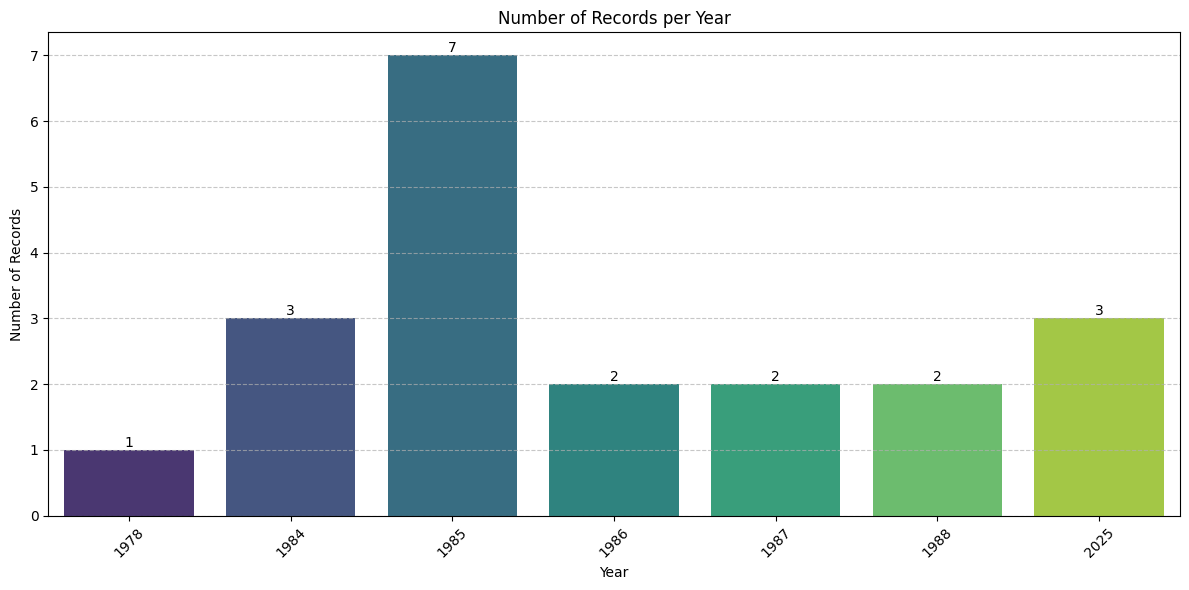

candidate_flag
non_candidate    19
candidate         1
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter out empty years and count records per year
year_counts = df[df['year'] != ''].groupby('year').size().reset_index(name='count')

# Sort by year for better visualization
year_counts['year'] = pd.to_numeric(year_counts['year'])
year_counts = year_counts.sort_values('year')

plt.figure(figsize=(12, 6))
ax = sns.barplot(x='year', y='count', data=year_counts, palette='viridis')
plt.title('Number of Records per Year')
plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Add counts on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.show()

print(df['candidate_flag'].value_counts())

In [ ]:
df_before_2000 = df[pd.to_numeric(df['year'], errors='coerce') < 2000]

print(f"Number of research records published before 2000: {len(df_before_2000)}")
display(df_before_2000.head())

Number of research records published before 2000: 17


,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,...,this thesis is a study of properties of certai...,1,maori,non_candidate,,,,,,
3,1de8b5fe-7274-45f6-b36b-1f699e2e70c1,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18179,University of Waikato Theses,Higher Degree Theses,Thesis,The transition to parenthood in New Zealand an...,"Swain, David",1985,1985,...,the research and reflection reported in this t...,0,,non_candidate,,,,,,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,...,forty-seven thermal pool sites in the central ...,1,rohe,non_candidate,,,,,,
5,3ee283d5-4ace-4baa-9527-e1275311885c,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18177,University of Waikato Theses,Higher Degree Theses,Thesis,Investigations on the taxonomy and the genetic...,"Martin, Andrea Muriel",1985,1985,...,the technique of pyrolysis mass spectrometry w...,0,,non_candidate,,,,,,
6,bff52c84-f4d1-4f15-8c21-46f777aa8ff7,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18176,University of Waikato Theses,Higher Degree Theses,Thesis,Secondary school subject choice: an ethnograph...,"Darnell, Doreen Anne",1985,1985,...,this study of subject choice followed two grou...,1,maori,non_candidate,,,,,,


In [ ]:
df_after_2000 = df[pd.to_numeric(df['year'], errors='coerce') > 2000]

print(f"Number of research records published after 2000: {len(df_after_2000)}")
display(df_after_2000.head())

Number of research records published after 2000: 3


,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,...,this thesis explores the experiences of rangat...,4,kaupapa; māori; rangatiratanga; whānau,candidate,,,,,,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,...,efficient thermal management is crucial for ne...,0,,non_candidate,,,,,,
19,dddf0725-94a6-4e28-94b3-87b357228f80,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18163,University of Waikato Theses,Higher Degree Theses,Thesis,Quantitative characterisation of near and subs...,"Kopf, Larissa",2025,2025,...,a mobile line scanning thermography (lst) setu...,0,,non_candidate,,,,,,


In [ ]:
soup = get_soup(START_URL)
print(soup.prettify())

<!DOCTYPE html>
<html lang="en">
 <head>
  <meta charset="utf-8"/>
  <base href="/"/>
  <title>
   Higher Degree Theses
  </title>
  <meta content="width=device-width,minimum-scale=1" name="viewport"/>
  <meta content="no-store" http-equiv="cache-control"/>
  <script data-cf-settings="cda2dd109deb21a49baf5177-|49" src="/cdn-cgi/scripts/7d0fa10a/cloudflare-static/rocket-loader.min.js">
  </script>
  <link href="styles.e382c7dd35ca1222.css" media="print" onload="this.media='all'" rel="stylesheet"/>
  <noscript>
   <link href="styles.e382c7dd35ca1222.css" rel="stylesheet"/>
  </noscript>
  <link class="theme-css" href="dspace-theme.css" rel="stylesheet" type="text/css"/>
  <link class="theme-head-tag" href="assets/images/favicon.ico" rel="icon" sizes="any"/>
  <link class="theme-head-tag" href="assets/images/favicon.ico" rel="icon" type="image/svg+xml"/>
  <link class="theme-head-tag" href="assets/dspace/images/favicons/apple-touch-icon.png" rel="apple-touch-icon"/>
  <link class="theme-h

Please examine the HTML output above. Look for elements related to pagination. Specifically, search for:

*   `<a rel="next" href="...">`
*   `<a>` tags containing text like "Next", ">", or "»"
*   Any other `<a>` tags that might indicate page numbers or navigation.

Once you identify the correct selector for the next page link, let me know, and we can adjust the `find_next_page` function.

In [ ]:
rows = []

for url in tqdm(collection_urls[:TARGET_N]):
    try:
        row = parse_item(url)
        rows.append(row)
    except Exception as e:
        rows.append({
            "record_id": "",
            "item_url": url,
            "permanent_link": "",
            "community": "University of Waikato Theses",
            "collection": "Higher Degree Theses",
            "item_type": "",
            "title": "",
            "authors": "",
            "year": "",
            "date": "",
            "degree": "",
            "supervisor": "",
            "subjects": "",
            "abstract": "",
            "citation": "",
            "file_available": False,
            "file_name": "",
            "file_url": "",
            "rights": "",
            "notes": f"ERROR: {type(e).__name__}: {e}"
        })
    time.sleep(DELAY_SECONDS)

df = pd.DataFrame(rows)
print(f"DataFrame now has {len(df)} rows.")
display(df.head())

  0%|          | 0/20 [00:00<?, ?it/s]

DataFrame now has 20 rows.


,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,degree,supervisor,subjects,abstract,citation,file_available,file_name,file_url,rights,notes
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,Doctor of Philosophy (PhD),"Tiakiwai, Sarah-Jane Whaanga, Hēmi",,This thesis explores the experiences of rangat...,,True,thesis.pdf (4.49 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,Doctor of Philosophy (PhD),"Torrens, Rob Yang, Fei Bolzoni, Leandro",,Efficient thermal management is crucial for ne...,,True,thesis.pdf (13.91 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,Doctor of Philosophy (PhD),"Mackay, K.",,This thesis is a study of properties of certai...,,True,thesis.pdf (10.81 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
3,1de8b5fe-7274-45f6-b36b-1f699e2e70c1,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18179,University of Waikato Theses,Higher Degree Theses,Thesis,The transition to parenthood in New Zealand an...,"Swain, David",1985,1985,Doctor of Philosophy (PhD),"Bettison, David Pool, Ian",,The research and reflection reported in this t...,,True,thesisvol1.pdf (21.22 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,Doctor of Philosophy (PhD),"Daniel, Roy M.",,Forty-seven thermal pool sites in the central ...,,True,thesis.pdf (44.36 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,


In [ ]:
collection_urls = []
seen = set()

current_url = START_URL
page_count = 0

while current_url and len(collection_urls) < TARGET_N:
    page_count += 1
    print(f"Collection page {page_count}: {current_url}")

    soup = get_soup(current_url)
    item_links = extract_item_links(soup)

    for link in item_links:
        if link not in seen:
            seen.add(link)
            collection_urls.append(link)
            if len(collection_urls) >= TARGET_N:
                break

    if len(collection_urls) >= TARGET_N:
        break

    next_url = find_next_page(soup, current_url)
    if not next_url or next_url == current_url:
        break

    current_url = next_url
    time.sleep(DELAY_SECONDS)

print(f"Collected {len(collection_urls)} item URLs")
collection_urls[:10]

Collection page 1: https://researchcommons.waikato.ac.nz/collections/c04b1b5e-510a-466b-b0fc-513765b3b6ee
DEBUG: find_next_page called for URL: https://researchcommons.waikato.ac.nz/collections/c04b1b5e-510a-466b-b0fc-513765b3b6ee
DEBUG: Pagination UL content:
<ul class="pagination">
 <!-- -->
 <li class="page-item disabled ng-star-inserted">
  <a aria-disabled="true" aria-label="Previous" class="page-link" href="" tabindex="-1">
   <span aria-hidden="true" class="ng-star-inserted">
    «
   </span>
   <!-- -->
  </a>
 </li>
 <!-- -->
 <li aria-current="page" class="page-item active ng-star-inserted">
  <!-- -->
  <a class="page-link ng-star-inserted" href="">
   1
   <span class="sr-only ng-star-inserted">
    (current)
   </span>
   <!-- -->
   <!-- -->
  </a>
  <!-- -->
 </li>
 <li class="page-item ng-star-inserted">
  <!-- -->
  <a class="page-link ng-star-inserted" href="">
   2
   <!-- -->
   <!-- -->
  </a>
  <!-- -->
 </li>
 <li class="page-item ng-star-inserted">
  <!-- -->
  

['https://researchcommons.waikato.ac.nz/entities/publication/b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0',
 'https://researchcommons.waikato.ac.nz/entities/publication/43044e62-b1a6-4e64-a4fe-58097449387f',
 'https://researchcommons.waikato.ac.nz/entities/publication/04c6eff7-6481-4ef8-8b35-382f84397f28',
 'https://researchcommons.waikato.ac.nz/entities/publication/1de8b5fe-7274-45f6-b36b-1f699e2e70c1',
 'https://researchcommons.waikato.ac.nz/entities/publication/1cf92d55-0bc5-455e-9a9b-bc1995213499',
 'https://researchcommons.waikato.ac.nz/entities/publication/3ee283d5-4ace-4baa-9527-e1275311885c',
 'https://researchcommons.waikato.ac.nz/entities/publication/bff52c84-f4d1-4f15-8c21-46f777aa8ff7',
 'https://researchcommons.waikato.ac.nz/entities/publication/ba3905be-abeb-4d1b-96ce-39fd69baca05',
 'https://researchcommons.waikato.ac.nz/entities/publication/d86b49ab-d3df-4666-8b61-fccc083df1e6',
 'https://researchcommons.waikato.ac.nz/entities/publication/5b7ac85e-aec1-4a19-934d-816884361258']

In [ ]:
rows = []

for url in tqdm(collection_urls[:TARGET_N]):
    try:
        row = parse_item(url)
        rows.append(row)
    except Exception as e:
        rows.append({
            "record_id": "",
            "item_url": url,
            "permanent_link": "",
            "community": "University of Waikato Theses",
            "collection": "Higher Degree Theses",
            "item_type": "",
            "title": "",
            "authors": "",
            "year": "",
            "date": "",
            "degree": "",
            "supervisor": "",
            "subjects": "",
            "abstract": "",
            "citation": "",
            "file_available": False,
            "file_name": "",
            "file_url": "",
            "rights": "",
            "notes": f"ERROR: {type(e).__name__}: {e}"
        })
    time.sleep(DELAY_SECONDS)

df = pd.DataFrame(rows)
print(f"DataFrame now has {len(df)} rows.")
display(df.head())

  0%|          | 0/20 [00:00<?, ?it/s]

DataFrame now has 20 rows.


,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,degree,supervisor,subjects,abstract,citation,file_available,file_name,file_url,rights,notes
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,Doctor of Philosophy (PhD),"Tiakiwai, Sarah-Jane Whaanga, Hēmi",,This thesis explores the experiences of rangat...,,True,thesis.pdf (4.49 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,Doctor of Philosophy (PhD),"Torrens, Rob Yang, Fei Bolzoni, Leandro",,Efficient thermal management is crucial for ne...,,True,thesis.pdf (13.91 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,Doctor of Philosophy (PhD),"Mackay, K.",,This thesis is a study of properties of certai...,,True,thesis.pdf (10.81 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
3,1de8b5fe-7274-45f6-b36b-1f699e2e70c1,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18179,University of Waikato Theses,Higher Degree Theses,Thesis,The transition to parenthood in New Zealand an...,"Swain, David",1985,1985,Doctor of Philosophy (PhD),"Bettison, David Pool, Ian",,The research and reflection reported in this t...,,True,thesisvol1.pdf (21.22 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,Doctor of Philosophy (PhD),"Daniel, Roy M.",,Forty-seven thermal pool sites in the central ...,,True,thesis.pdf (44.36 MB),https://researchcommons.waikato.ac.nz/bitstrea...,All items in Research Commons are provided for...,


In [ ]:
for col in ["title", "subjects", "abstract"]:
    df[f"{col}_clean"] = df[col].fillna("").map(clean_text)

# placeholder columns for later scoring / labeling
extra_cols = [
    "rule_score", "rule_hits", "candidate_flag",
    "llm_label", "llm_confidence", "llm_reason",
    "human_label", "human_notes", "final_label"
]

for col in extra_cols:
    if col not in df.columns:
        df[col] = ""

display(df.head())

,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,...,this thesis explores the experiences of rangat...,,,,,,,,,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,...,efficient thermal management is crucial for ne...,,,,,,,,,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,...,this thesis is a study of properties of certai...,,,,,,,,,
3,1de8b5fe-7274-45f6-b36b-1f699e2e70c1,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18179,University of Waikato Theses,Higher Degree Theses,Thesis,The transition to parenthood in New Zealand an...,"Swain, David",1985,1985,...,the research and reflection reported in this t...,,,,,,,,,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,...,forty-seven thermal pool sites in the central ...,,,,,,,,,


In [ ]:
MAORI_TERMS = [
    "māori", "maori", "te reo", "te tiriti", "treaty",
    "iwi", "hapū", "hapu", "whānau", "whanau",
    "mātauranga", "matauranga", "tikanga", "kaupapa",
    "rangatiratanga", "taonga", "rohe", "marae", "whenua",
    "kaitiakitanga"
]

def seed_score(row):
    text = " ".join([
        str(row.get("title_clean", "")),
        str(row.get("subjects_clean", "")),
        str(row.get("abstract_clean", ""))
    ])
    hits = [t for t in MAORI_TERMS if t in text]
    return len(set(hits)), "; ".join(sorted(set(hits)))

df[["rule_score", "rule_hits"]] = df.apply(
    lambda r: pd.Series(seed_score(r)), axis=1
)

df["candidate_flag"] = df["rule_score"].apply(lambda x: "candidate" if x >= 2 else "non_candidate")
display(df.sort_values(["rule_score", "year"], ascending=[False, False]).head())

,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,...,this thesis explores the experiences of rangat...,4,kaupapa; māori; rangatiratanga; whānau,candidate,,,,,,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,...,this thesis is a study of properties of certai...,1,maori,non_candidate,,,,,,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,...,forty-seven thermal pool sites in the central ...,1,rohe,non_candidate,,,,,,
6,bff52c84-f4d1-4f15-8c21-46f777aa8ff7,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18176,University of Waikato Theses,Higher Degree Theses,Thesis,Secondary school subject choice: an ethnograph...,"Darnell, Doreen Anne",1985,1985,...,this study of subject choice followed two grou...,1,maori,non_candidate,,,,,,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,...,efficient thermal management is crucial for ne...,0,,non_candidate,,,,,,


In [ ]:
for col in ["title", "subjects", "abstract"]:
    df[f"{col}_clean"] = df[col].fillna("").map(clean_text)

# placeholder columns for later scoring / labeling
extra_cols = [
    "rule_score", "rule_hits", "candidate_flag",
    "llm_label", "llm_confidence", "llm_reason",
    "human_label", "human_notes", "final_label"
]

for col in extra_cols:
    if col not in df.columns:
        df[col] = ""

display(df.head())

,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,...,this thesis explores the experiences of rangat...,,,,,,,,,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,...,efficient thermal management is crucial for ne...,,,,,,,,,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,...,this thesis is a study of properties of certai...,,,,,,,,,
3,1de8b5fe-7274-45f6-b36b-1f699e2e70c1,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18179,University of Waikato Theses,Higher Degree Theses,Thesis,The transition to parenthood in New Zealand an...,"Swain, David",1985,1985,...,the research and reflection reported in this t...,,,,,,,,,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,...,forty-seven thermal pool sites in the central ...,,,,,,,,,


In [ ]:
MAORI_TERMS = [
    "māori", "maori", "te reo", "te tiriti", "treaty",
    "iwi", "hapū", "hapu", "whānau", "whanau",
    "mātauranga", "matauranga", "tikanga", "kaupapa",
    "rangatiratanga", "taonga", "rohe", "marae", "whenua",
    "kaitiakitanga"
]

def seed_score(row):
    text = " ".join([
        str(row.get("title_clean", "")),
        str(row.get("subjects_clean", "")),
        str(row.get("abstract_clean", ""))
    ])
    hits = [t for t in MAORI_TERMS if t in text]
    return len(set(hits)), "; ".join(sorted(set(hits)))

df[["rule_score", "rule_hits"]] = df.apply(
    lambda r: pd.Series(seed_score(r)), axis=1
)

df["candidate_flag"] = df["rule_score"].apply(lambda x: "candidate" if x >= 2 else "non_candidate")
display(df.sort_values(["rule_score", "year"], ascending=[False, False]).head())

,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,...,this thesis explores the experiences of rangat...,4,kaupapa; māori; rangatiratanga; whānau,candidate,,,,,,
2,04c6eff7-6481-4ef8-8b35-382f84397f28,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18180,University of Waikato Theses,Higher Degree Theses,Thesis,Studies on the conservation of waterlogged woo...,"Wallace, Roderick Thomas",1985,1985,...,this thesis is a study of properties of certai...,1,maori,non_candidate,,,,,,
4,1cf92d55-0bc5-455e-9a9b-bc1995213499,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18178,University of Waikato Theses,Higher Degree Theses,Thesis,Cellulases from extremely thermophilic anaerob...,"Sharrock, Keith R.",1985,1985,...,forty-seven thermal pool sites in the central ...,1,rohe,non_candidate,,,,,,
6,bff52c84-f4d1-4f15-8c21-46f777aa8ff7,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18176,University of Waikato Theses,Higher Degree Theses,Thesis,Secondary school subject choice: an ethnograph...,"Darnell, Doreen Anne",1985,1985,...,this study of subject choice followed two grou...,1,maori,non_candidate,,,,,,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,...,efficient thermal management is crucial for ne...,0,,non_candidate,,,,,,


In [ ]:
df_2000_to_2025 = df[(pd.to_numeric(df['year'], errors='coerce') >= 2000) & (pd.to_numeric(df['year'], errors='coerce') <= 2025)]

print(f"Number of research records published between 2000 and 2025: {len(df_2000_to_2025)}")
display(df_2000_to_2025.head())

Number of research records published between 2000 and 2025: 3


,record_id,item_url,permanent_link,community,collection,item_type,title,authors,year,date,...,abstract_clean,rule_score,rule_hits,candidate_flag,llm_label,llm_confidence,llm_reason,human_label,human_notes,final_label
0,b3b0e4d0-bf3e-4010-83fd-790fc2c99cb0,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18186,University of Waikato Theses,Higher Degree Theses,Thesis,Ka hao te rangatahi: Exploring school and work...,"Maihi, Bonnie",2025,2025,...,this thesis explores the experiences of rangat...,4,kaupapa; māori; rangatiratanga; whānau,candidate,,,,,,
1,43044e62-b1a6-4e64-a4fe-58097449387f,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18184,University of Waikato Theses,Higher Degree Theses,Thesis,"Investigation on fabrication, interface format...","Ma, Jingnan",2025,2025,...,efficient thermal management is crucial for ne...,0,,non_candidate,,,,,,
19,dddf0725-94a6-4e28-94b3-87b357228f80,https://researchcommons.waikato.ac.nz/entities...,https://hdl.handle.net/10289/18163,University of Waikato Theses,Higher Degree Theses,Thesis,Quantitative characterisation of near and subs...,"Kopf, Larissa",2025,2025,...,a mobile line scanning thermography (lst) setu...,0,,non_candidate,,,,,,
